# Rancangan Eksperimen — Studio Proyek 3 (NLP)

## 1. Pemilihan Dataset, Pembersihan & Pembagian Data
* **Dataset**: **SmSA (*Sentiment Analysis*)** dari benchmark **IndoNLU**, berisi kalimat ulasan dan media sosial berbahasa Indonesia dengan 3 kelas sentimen (`positive`, `neutral`, `negative`). Dataset ini relevan untuk kasus klasifikasi sentimen multi-kelas Bahasa Indonesia dengan tantangan ketidakseimbangan distribusi kelas (kelas `neutral` merupakan kelas minoritas).
* **Pembersihan & Pembagian Data**:
  1. Pembersihan teks berlabel bertentangan, penghapusan duplikat pada data latih, serta penghapusan data validasi yang tumpang tindih (*overlap*) dengan data latih.
  2. Pembatasan data latih menjadi **6.000 sampel** menggunakan ***stratified sampling*** (`random_state=42`) sehingga proporsi ketiga kelas (`positive`, `neutral`, `negative`) tetap terjaga dan identik di seluruh *backbone*, strategi *fine-tuning*, maupun *baseline* TF-IDF.
  3. **Komposisi Final Dataset**: `train` = **6.000 sampel**, `validation` = **1.246 sampel**, dan `test` = **500 sampel**.

## 2. Variabel Terkendali & Protokol Evaluasi
* **Variabel Terkendali (Dikunci)**:
  * `max_length` = `128`
  * `train_batch_size` = `16`, `eval_batch_size` = `32`
  * `epochs` = `3`
  * `weight_decay` = `0.01`, `max_grad_norm` = `1.0`
  * `random_seed` = `[42, 123, 2026]` (diterapkan melalui fungsi `set_reproducible_seed()` pada setiap *run*)
  * `learning_rate` = `2e-5` untuk *Full Fine-Tuning* dan *Partial Freezing*; `2e-3` untuk *Linear Probing*
* **Pemilihan Epoch & Evaluasi Test Set**:
  * Pada setiap *run*, evaluasi `Validation Macro F1` dilakukan pada akhir setiap epoch dan bobot model terbaik (*best checkpoint*) disimpan.
  * Evaluasi pada **Test Set (500 sampel)** dilakukan **satu kali** per *run* menggunakan *checkpoint* terbaik tersebut, dan waktu inferensi (`ms/kalimat`) diukur pada perangkat GPU serta sesi yang seragam.

## 3. Matriks Eksperimen (3 Backbone × 3 Strategi × 3 Seed = 27 Run)
| Backbone | Model Checkpoint | Full Fine-Tuning (`lr=2e-5`) | Partial Freezing (`lr=2e-5`) | Linear Probing (`lr=2e-3`) |
| :--- | :--- | :---: | :---: | :---: |
| **BERT** | `bert-base-multilingual-cased` | Seed 42, 123, 2026 | Seed 42, 123, 2026 | Seed 42, 123, 2026 |
| **DistilBERT** | `distilbert-base-multilingual-cased` | Seed 42, 123, 2026 | Seed 42, 123, 2026 | Seed 42, 123, 2026 |
| **IndoBERT** | `indobenchmark/indobert-base-p1` | Seed 42, 123, 2026 | Seed 42, 123, 2026 | Seed 42, 123, 2026 |

## 4. Hipotesis Penelitian (H1–H3)
* **H1 (Pengaruh Arsitektur Backbone)**: IndoBERT (indobenchmark/indobert-base-p1) diperkirakan menghasilkan skor Validation Macro F1 tertinggi dibandingkan BERT multilingual dan DistilBERT multilingual pada setiap strategi fine-tuning yang diuji. Hal ini didasarkan pada prapelatihan IndoBERT menggunakan korpus Bahasa Indonesia yang memungkinkan model mempelajari karakteristik bahasa dan konteks semantik yang lebih sesuai dengan dataset SmSA.
* **H2 (Efisiensi Waktu Pelatihan dan Inferensi)**: DistilBERT (distilbert-base-multilingual-cased) diperkirakan memiliki waktu pelatihan dan inferensi yang lebih singkat dibandingkan BERT multilingual dan IndoBERT. Hal ini berkaitan dengan pengurangan jumlah layer encoder dari 12 menjadi 6, sehingga komputasi yang diperlukan lebih sedikit. Efisiensi tersebut diperkirakan dapat disertai penurunan performa Macro F1 dibandingkan backbone lain.
* **H3 (Efektivitas Strategi Fine-Tuning Hemat Komputasi)**: Full Fine-Tuning dan Partial Freezing diperkirakan menghasilkan performa Macro F1 lebih tinggi dibandingkan Linear Probing. Partial Freezing diharapkan dapat mempertahankan performa yang kompetitif dibandingkan Full Fine-Tuning dengan mengurangi jumlah parameter yang dilatih, waktu pelatihan, dan penggunaan memori GPU. Sementara itu, Linear Probing diperkirakan memiliki waktu pelatihan paling singkat, tetapi berpotensi menghasilkan performa Macro F1 lebih rendah karena parameter encoder tidak diperbarui selama pelatihan.

In [1]:
import pandas as pd
import numpy as np
import re
import unicodedata
import os

pd.set_option("display.max_colwidth", 120)

print("Pandas version:", pd.__version__)
print("Environment siap.")

Pandas version: 2.3.3
Environment siap.


In [2]:
# ==============================================================================
# PEMERIKSAAN LINGKUNGAN EKSEKUSI & PROTOKOL REPRODUKSIBILITAS
# ==============================================================================
import os
import sys
import json
import platform
import torch
import numpy as np
import pandas as pd
import matplotlib
import sklearn
import transformers

# 1. Deteksi Platform Cloud (Kaggle / Google Colab)
is_kaggle = os.path.exists("/kaggle/working")
is_colab = "google.colab" in sys.modules
cloud_platform = "Kaggle Notebook" if is_kaggle else ("Google Colab" if is_colab else "Lokal / Lainnya")

assert is_kaggle or is_colab, (
    "Peringatan: Spesifikasi mewajibkan eksekusi pada platform cloud (Kaggle Notebook atau Google Colab)."
)

# 2. Verifikasi GPU Aktif
assert torch.cuda.is_available(), (
    "GPU tidak terdeteksi! Aktifkan akselerator GPU pada pengaturan Kaggle/Colab sebelum menjalankan eksperimen."
)
gpu_name = torch.cuda.get_device_name(0)
gpu_vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)

# 3. Verifikasi Ketersediaan Library Wajib
required_libs = {
    "Python": sys.version.split()[0],
    "PyTorch": torch.__version__,
    "Transformers": transformers.__version__,
    "Scikit-Learn": sklearn.__version__,
    "Pandas": pd.__version__,
    "NumPy": np.__version__,
    "Matplotlib": matplotlib.__version__,
}

# 4. Ringkasan Protokol Reproduksibilitas & Pengukuran Inferensi
env_report = {
    "platform": cloud_platform,
    "gpu_device": gpu_name,
    "gpu_vram_gb": round(gpu_vram_gb, 2),
    "cuda_version": torch.version.cuda,
    "libraries": required_libs,
    "reproducibility_policy": {
        "seeds": [42, 123, 2026],
        "seed_function": "set_reproducible_seed(seed) dipanggil sebelum setiap inisialisasi dataloader dan model",
        "inference_benchmark_protocol": (
            "Diukur pada GPU yang sama dalam satu sesi menggunakan eval_batch_size=32, "
            "mode model.eval(), torch.no_grad(), dan torch.cuda.synchronize()."
        ),
    },
}

print("=== VERIFIKASI LINGKUNGAN & REPRODUKSIBILITAS ===")
print(f"Platform Cloud : {cloud_platform}")
print(f"Perangkat GPU  : {gpu_name} ({gpu_vram_gb:.2f} GB VRAM) [Tesla T4 sebagai acuan estimasi waktu]")
for lib_name, lib_ver in required_libs.items():
    print(f"  - {lib_name:14s}: {lib_ver}")

os.makedirs("/kaggle/working/studio3_results", exist_ok=True)
with open("/kaggle/working/studio3_results/environment_manifest_v4.json", "w") as f:
    json.dump(env_report, f, indent=2)
print("\nStatus: Seluruh syarat lingkungan & reproduksibilitas TERPENUHI.")

=== VERIFIKASI LINGKUNGAN & REPRODUKSIBILITAS ===
Platform Cloud : Kaggle Notebook
Perangkat GPU  : Tesla T4 (14.56 GB VRAM) [Tesla T4 sebagai acuan estimasi waktu]
  - Python        : 3.13.16
  - PyTorch       : 2.11.0+cu130
  - Transformers  : 5.20.2
  - Scikit-Learn  : 1.6.1
  - Pandas        : 2.3.3
  - NumPy         : 2.1.3
  - Matplotlib    : 3.10.0

Status: Seluruh syarat lingkungan & reproduksibilitas TERPENUHI.


# Dataset Extraction dan Preprocessing

In [3]:
# URL dataset SmSA dari repositori resmi IndoNLU
BASE_URL = (
    "https://raw.githubusercontent.com/"
    "IndoNLP/indonlu/master/dataset/"
    "smsa_doc-sentiment-prosa/"
)

DATA_URLS = {
    "train": BASE_URL + "train_preprocess.tsv",
    "validation": BASE_URL + "valid_preprocess.tsv",
    "test": BASE_URL + "test_preprocess.tsv"
}


def load_smsa(url, split_name):
    """
    Membaca file TSV SmSA.
    Setiap baris terdiri dari teks dan label sentimen.
    """
    df = pd.read_csv(
        url,
        sep="\t",
        header=None,
        names=["text", "label"],
        dtype="string",
        keep_default_na=False
    )

    print(f"{split_name}: {len(df):,} baris berhasil dimuat.")

    return df


raw_splits = {
    split: load_smsa(url, split)
    for split, url in DATA_URLS.items()
}

print("\nPengambilan dataset selesai.")

train: 11,000 baris berhasil dimuat.
validation: 1,260 baris berhasil dimuat.
test: 500 baris berhasil dimuat.

Pengambilan dataset selesai.


In [4]:
for split_name, df in raw_splits.items():

    print(f"\n{'='*50}")
    print(f"DATASET: {split_name.upper()}")
    print(f"{'='*50}")

    print("Jumlah data:", len(df))
    print("\nInformasi kolom:")
    print(df.info())

    print("\nContoh data:")
    display(df.head(5))

    print("\nDistribusi label:")
    print(df["label"].value_counts())

    print("\nMissing value:")
    print(df.isna().sum())


DATASET: TRAIN
Jumlah data: 11000

Informasi kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11000 entries, 0 to 10999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    11000 non-null  string
 1   label   11000 non-null  string
dtypes: string(2)
memory usage: 172.0 KB
None

Contoh data:


,text,label
0,warung ini dimiliki oleh pengusaha pabrik tahu yang sudah puluhan tahun terkenal membuat tahu putih di bandung . tah...,positive
1,mohon ulama lurus dan k212 mmbri hujjah partai apa yang harus diwlh agar suara islam tidak pecah-pecah,neutral
2,"lokasi strategis di jalan sumatera bandung . tempat nya nyaman terutama sofa di lantai 2 . paella nya enak , sangat ...",positive
3,betapa bahagia nya diri ini saat unboxing paket dan barang nya bagus ! menetapkan beli lagi !,positive
4,"duh . jadi mahasiswa jangan sombong dong . kasih kartu kuning segala . belajar dulu yang baik , tidak usahlah ikut-i...",negative



Distribusi label:
label
positive    6416
negative    3436
neutral     1148
Name: count, dtype: Int64

Missing value:
text     0
label    0
dtype: int64

DATASET: VALIDATION
Jumlah data: 1260

Informasi kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1260 entries, 0 to 1259
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    1260 non-null   string
 1   label   1260 non-null   string
dtypes: string(2)
memory usage: 19.8 KB
None

Contoh data:


,text,label
0,"meski masa kampanye sudah selesai , bukan berati habis pula upaya mengerek tingkat kedipilihan elektabilitas .",neutral
1,tidak enak,negative
2,"restoran ini menawarkan makanan sunda . kami memesan ayam goreng , kangkung , sayur asam , ikan gurame goreng , ikan...",positive
3,"lokasi di alun alun masakan padang ini cukup terkenal dengan kepala ikan kakap gule , biasa saya pesan nasi bungkus ...",positive
4,"betapa bejad kader gerindra yang anggota dprd mencabuli anak smp , rakyat harus cerdas partai mana yang harus di ten...",negative



Distribusi label:
label
positive    735
negative    394
neutral     131
Name: count, dtype: Int64

Missing value:
text     0
label    0
dtype: int64

DATASET: TEST
Jumlah data: 500

Informasi kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    500 non-null    string
 1   label   500 non-null    string
dtypes: string(2)
memory usage: 7.9 KB
None

Contoh data:


,text,label
0,kemarin gue datang ke tempat makan baru yang ada di dago atas . gue kira makanan nya enak karena harga nya mahal . t...,negative
1,"kayak nya sih gue tidak akan mau balik lagi ke tempat itu . gila , ya , gue enggak ngerti kenapa tempat nya dibiarka...",negative
2,"kalau dipikir-pikir , sebenarnya tidak ada yang bisa dibanggakan dari jokowi . pertama , dia tidak bisa nepatin janj...",negative
3,ini pertama kalinya gua ke bank buat ngurusin pembuatan rekening baru . nama nya juga orang pertama kali ya baru ke ...,negative
4,waktu sampai dengan gue pernah disuruh ibu latihan karate . kata nya biar gue bisa melawan penjahat kalau ada laki-l...,negative



Distribusi label:
label
positive    208
negative    204
neutral      88
Name: count, dtype: Int64

Missing value:
text     0
label    0
dtype: int64


In [5]:
# Pemetaan label mengikuti konfigurasi SmSA IndoNLU
LABEL2ID = {
    "positive": 0,
    "neutral": 1,
    "negative": 2
}

ID2LABEL = {
    value: key
    for key, value in LABEL2ID.items()
}


def normalize_text(text):
    """
    Normalisasi ringan tanpa mengubah isi semantik.
    """
    text = unicodedata.normalize("NFC", str(text))

    # Mengganti whitespace berulang dengan satu spasi
    text = re.sub(r"\s+", " ", text)

    return text.strip()


def basic_clean(df, split_name):
    df = df.copy()

    # Normalisasi teks
    df["text"] = df["text"].apply(normalize_text)

    # Normalisasi label
    df["label"] = df["label"].str.strip().str.lower()

    before = len(df)

    # Hapus teks kosong
    df = df[df["text"].str.len() > 0]

    # Hapus label yang tidak dikenal
    df = df[df["label"].isin(LABEL2ID)]

    # Encode label menjadi integer
    df["label_id"] = df["label"].map(LABEL2ID).astype("int64")

    removed = before - len(df)

    print(
        f"{split_name}: {before:,} -> {len(df):,} "
        f"(dihapus: {removed:,})"
    )

    return df.reset_index(drop=True)


clean_splits = {
    split: basic_clean(df, split)
    for split, df in raw_splits.items()
}

train: 11,000 -> 11,000 (dihapus: 0)
validation: 1,260 -> 1,260 (dihapus: 0)
test: 500 -> 500 (dihapus: 0)


In [6]:
# Gabungkan seluruh split untuk audit label
combined = pd.concat(
    [
        df.assign(split=split_name)
        for split_name, df in clean_splits.items()
    ],
    ignore_index=True
)

# Hitung jumlah label unik pada setiap teks
label_counts = combined.groupby("text")["label"].nunique()

# Teks dengan lebih dari satu label
conflicting_texts = set(
    label_counts[label_counts > 1].index
)

print("Jumlah teks dengan label bertentangan:",
      len(conflicting_texts))

# Hapus seluruh teks yang memiliki label bertentangan
for split_name in clean_splits:

    before = len(clean_splits[split_name])

    clean_splits[split_name] = (
        clean_splits[split_name]
        [
            ~clean_splits[split_name]["text"].isin(conflicting_texts)
        ]
        .reset_index(drop=True)
    )

    after = len(clean_splits[split_name])

    print(
        f"{split_name}: {before:,} -> {after:,} "
        f"(dihapus: {before-after:,})"
    )

Jumlah teks dengan label bertentangan: 0
train: 11,000 -> 11,000 (dihapus: 0)
validation: 1,260 -> 1,260 (dihapus: 0)
test: 500 -> 500 (dihapus: 0)


In [7]:
# Hapus duplikat dalam masing-masing split
for split_name in clean_splits:

    before = len(clean_splits[split_name])

    clean_splits[split_name] = (
        clean_splits[split_name]
        .drop_duplicates(subset=["text"], keep="first")
        .reset_index(drop=True)
    )

    after = len(clean_splits[split_name])

    print(
        f"{split_name}: {before:,} -> {after:,} "
        f"(duplikat dihapus: {before-after:,})"
    )


# Hapus data validation yang muncul pada train
train_texts = set(clean_splits["train"]["text"])

before = len(clean_splits["validation"])

clean_splits["validation"] = (
    clean_splits["validation"]
    [
        ~clean_splits["validation"]["text"].isin(train_texts)
    ]
    .reset_index(drop=True)
)

after = len(clean_splits["validation"])

print("\nPembersihan overlap validation:")
print("Sebelum:", before)
print("Sesudah:", after)
print("Dihapus:", before - after)

train: 11,000 -> 10,933 (duplikat dihapus: 67)
validation: 1,260 -> 1,260 (duplikat dihapus: 0)
test: 500 -> 500 (duplikat dihapus: 0)

Pembersihan overlap validation:
Sebelum: 1260
Sesudah: 1246
Dihapus: 14


In [8]:
# Ringkasan jumlah data
summary = pd.DataFrame({
    split_name: {
        "Jumlah data": len(df),
        "Jumlah label unik": df["label"].nunique(),
        "Duplikat teks": df["text"].duplicated().sum(),
        "Missing text": df["text"].isna().sum(),
        "Missing label": df["label"].isna().sum()
    }
    for split_name, df in clean_splits.items()
}).T

display(summary)

# Distribusi kelas
for split_name, df in clean_splits.items():

    print(f"\nDistribusi label: {split_name.upper()}")

    distribution = (
        df["label"]
        .value_counts()
        .reindex(LABEL2ID.keys(), fill_value=0)
    )

    display(distribution.to_frame("Jumlah"))

# Pemeriksaan overlap
train_texts = set(clean_splits["train"]["text"])
valid_texts = set(clean_splits["validation"]["text"])
test_texts = set(clean_splits["test"]["text"])

print("\nPemeriksaan overlap:")
print("Train - Validation:", len(train_texts & valid_texts))
print("Train - Test:", len(train_texts & test_texts))
print("Validation - Test:", len(valid_texts & test_texts))

,Jumlah data,Jumlah label unik,Duplikat teks,Missing text,Missing label
train,10933,3,0,0,0
validation,1246,3,0,0,0
test,500,3,0,0,0



Distribusi label: TRAIN


,Jumlah
label,
positive,6383
neutral,1138
negative,3412



Distribusi label: VALIDATION


,Jumlah
label,
positive,728
neutral,129
negative,389



Distribusi label: TEST


,Jumlah
label,
positive,208
neutral,88
negative,204



Pemeriksaan overlap:
Train - Validation: 0
Train - Test: 0
Validation - Test: 0


In [9]:
from sklearn.model_selection import train_test_split

SUBSET_TRAIN_SIZE = 6000
SUBSET_SEED = 42  # Dikunci agar subset 6.000 data sama untuk seluruh backbone & strategi

print("Proporsi kelas SEBELUM sampling (10.933 data):")
print(clean_splits["train"]["label"].value_counts(normalize=True).round(4))

# Stratified sampling menjaga proporsi kelas positive, neutral, dan negative
train_subset, _ = train_test_split(
    clean_splits["train"],
    train_size=SUBSET_TRAIN_SIZE,
    stratify=clean_splits["train"]["label_id"],
    random_state=SUBSET_SEED,
)

# Timpa clean_splits["train"] dengan subset 6.000 data
clean_splits["train"] = train_subset.reset_index(drop=True)

print(f"\nJumlah data train SESUDAH sampling: {len(clean_splits['train']):,}")
print("Proporsi kelas SESUDAH sampling (6.000 data):")
print(clean_splits["train"]["label"].value_counts(normalize=True).round(4))
print("\nJumlah per kelas:")
print(clean_splits["train"]["label"].value_counts())

Proporsi kelas SEBELUM sampling (10.933 data):
label
positive    0.5838
negative    0.3121
neutral     0.1041
Name: proportion, dtype: Float64

Jumlah data train SESUDAH sampling: 6,000
Proporsi kelas SESUDAH sampling (6.000 data):
label
positive    0.5838
negative     0.312
neutral     0.1042
Name: proportion, dtype: Float64

Jumlah per kelas:
label
positive    3503
negative    1872
neutral      625
Name: count, dtype: Int64


In [10]:
OUTPUT_DIR = "/kaggle/working/smsa_preprocessed"

os.makedirs(OUTPUT_DIR, exist_ok=True)

for split_name, df in clean_splits.items():

    output_path = os.path.join(
        OUTPUT_DIR,
        f"smsa_{split_name}_clean.csv"
    )

    df.to_csv(
        output_path,
        index=False,
        encoding="utf-8"
    )

    print(f"Berhasil disimpan: {output_path}")


print("\nSemua dataset berhasil disimpan.")

Berhasil disimpan: /kaggle/working/smsa_preprocessed/smsa_train_clean.csv
Berhasil disimpan: /kaggle/working/smsa_preprocessed/smsa_validation_clean.csv
Berhasil disimpan: /kaggle/working/smsa_preprocessed/smsa_test_clean.csv

Semua dataset berhasil disimpan.


# Tahap 2 — Full Fine-Tuning

Bagian ini menjalankan **Full Fine-Tuning** untuk tiga backbone yang ditentukan dalam spesifikasi tugas: BERT multilingual, DistilBERT multilingual, dan IndoBERT.

Ketentuan eksperimen yang dikunci pada tahap ini:

- Dataset: hasil preprocessing SmSA dari `clean_splits`.
- Strategi: Full Fine-Tuning (seluruh parameter model dapat diperbarui).
- Jumlah kelas: 3.
- `max_length`: 128.
- `batch_size`: 16.
- `epoch`: 3.
- `learning_rate`: `2e-5`.
- Random seed: 42, 123, dan 2026.

Metrik utama dicatat pada **validation set** untuk perbandingan eksperimen. Test set tetap disimpan untuk evaluasi akhir setelah konfigurasi eksperimen dikunci.

In [11]:
# Instalasi versi library yang digunakan pada notebook ini.
# Jika Kaggle menampilkan pesan bahwa kernel perlu direstart, restart session
# lalu jalankan notebook kembali dari cell pertama.
# %pip install -q "transformers==4.57.6" "scikit-learn>=1.3"

In [12]:
import gc
import os
import time
from contextlib import nullcontext

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    set_seed,
)

import transformers

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print(
        "PERINGATAN: GPU tidak terdeteksi. Aktifkan GPU T4 pada pengaturan "
        "Kaggle sebelum menjalankan eksperimen penuh."
    )


PyTorch: 2.11.0+cu130
Transformers: 5.20.2
Device: cuda
GPU: Tesla T4


In [13]:
# Konfigurasi eksperimen — kunci nilai ini sebelum seluruh run dijalankan.
MODEL_CONFIGS = {
    "BERT": "bert-base-multilingual-cased",
    "DistilBERT": "distilbert-base-multilingual-cased",
    "IndoBERT": "indobenchmark/indobert-base-p1",
}

NUM_LABELS = 3
MAX_LENGTH = 128
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0
SEEDS = [42, 123, 2026]
USE_AMP = DEVICE.type == "cuda"

# Kode konfigurasi final v4 (train 6.000 + best epoch checkpoint + evaluasi test set seluruh run)
CONFIG_CODE = "fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4"
RESULTS_DIR = "/kaggle/working/studio3_results"
CONFUSION_DIR = os.path.join(RESULTS_DIR, "confusion_matrices")
REPORT_DIR = os.path.join(RESULTS_DIR, "classification_reports")
CHECKPOINT_DIR = os.path.join(RESULTS_DIR, "checkpoints")

for d in [RESULTS_DIR, CONFUSION_DIR, REPORT_DIR, CHECKPOINT_DIR]:
    os.makedirs(d, exist_ok=True)

RESULTS_CSV = os.path.join(RESULTS_DIR, f"hasil_smsa_{CONFIG_CODE}.csv")
AGGREGATE_CSV = os.path.join(RESULTS_DIR, f"rekap_agregat_smsa_{CONFIG_CODE}.csv")

# Pastikan hasil preprocessing 6.000 sampel dari cell sebelumnya tersedia.
required_splits = {"train", "validation", "test"}
assert "clean_splits" in globals(), "Jalankan seluruh cell preprocessing terlebih dahulu."
assert required_splits.issubset(clean_splits.keys()), "Split train/validation/test tidak lengkap."
assert len(clean_splits["train"]) == 6000, (
    f"Ukuran train saat ini {len(clean_splits['train'])}, pastikan sel stratified sampling 6.000 sudah dijalankan!"
)

for split_name in ["train", "validation", "test"]:
    required_cols = {"text", "label_id"}
    assert required_cols.issubset(clean_splits[split_name].columns), (
        f"Kolom {required_cols} tidak lengkap pada split {split_name}."
    )
    assert clean_splits[split_name]["label_id"].isin([0, 1, 2]).all(), (
        f"Ditemukan label di luar rentang 0-2 pada {split_name}."
    )

print("Konfigurasi eksperimen v4 siap.")
print("Jumlah data:", {k: len(clean_splits[k]) for k in ["train", "validation", "test"]})
print("AMP aktif:", USE_AMP)
print("Kode konfigurasi:", CONFIG_CODE)
print("File hasil:", RESULTS_CSV)

Konfigurasi eksperimen v4 siap.
Jumlah data: {'train': 6000, 'validation': 1246, 'test': 500}
AMP aktif: True
Kode konfigurasi: fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4
File hasil: /kaggle/working/studio3_results/hasil_smsa_fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4.csv


## Memahami head klasifikasi dan Full Fine-Tuning

`AutoModelForSequenceClassification` memuat backbone pretrained sekaligus menyiapkan classification head dengan **3 output**, sesuai label SmSA: positive, neutral, dan negative. Bobot encoder berasal dari checkpoint pretrained, sedangkan bobot head klasifikasi diinisialisasi untuk tugas klasifikasi ini.

Pada **Full Fine-Tuning**, seluruh parameter model harus memiliki `requires_grad=True` dan ikut diperbarui selama training. Kode memeriksa bahwa jumlah parameter yang dilatih sama dengan jumlah seluruh parameter.


In [14]:
class SmSADataset(Dataset):
    """Dataset PyTorch untuk teks SmSA yang sudah ditokenisasi."""

    def __init__(self, dataframe, tokenizer, max_length):
        texts = dataframe["text"].astype(str).tolist()
        labels = dataframe["label_id"].astype(int).tolist()

        self.encodings = tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=max_length,
            return_tensors="pt",
        )
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: value[idx] for key, value in self.encodings.items()}
        item["labels"] = self.labels[idx]
        return item


TOKENIZER_CACHE = {}


def get_tokenizer(model_key, model_id):
    """Memuat tokenizer satu kali untuk setiap backbone."""
    if model_key not in TOKENIZER_CACHE:
        print(f"Memuat tokenizer {model_key}: {model_id}")
        TOKENIZER_CACHE[model_key] = AutoTokenizer.from_pretrained(model_id)
    return TOKENIZER_CACHE[model_key]


def build_dataloaders(tokenizer, seed):
    train_dataset = SmSADataset(clean_splits["train"], tokenizer, MAX_LENGTH)
    valid_dataset = SmSADataset(clean_splits["validation"], tokenizer, MAX_LENGTH)

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=TRAIN_BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
    )
    valid_loader = DataLoader(
        valid_dataset,
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
    )

    return train_loader, valid_loader


In [15]:
def set_reproducible_seed(seed):
    """Mengatur random seed melalui fungsi resmi HuggingFace Transformers."""
    set_seed(seed)

    # Mengurangi variasi dari algoritma cuDNN yang nondeterministik.
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def autocast_context():
    if USE_AMP:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()


def count_parameters(model):
    total = sum(parameter.numel() for parameter in model.parameters())
    trainable = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )
    return total, trainable


def train_one_epoch(model, dataloader, optimizer, scaler):
    """Melatih satu epoch dan menghitung loss rata-rata berbobot jumlah sampel."""
    model.train()
    total_loss = 0.0
    total_examples = 0

    for batch in dataloader:
        labels = batch["labels"].to(DEVICE, non_blocking=True)
        inputs = {
            key: value.to(DEVICE, non_blocking=True)
            for key, value in batch.items()
            if key != "labels"
        }

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            outputs = model(**inputs, labels=labels)
            loss = outputs.loss

        if USE_AMP:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            optimizer.step()

        batch_size = labels.size(0)
        total_loss += float(loss.detach().cpu()) * batch_size
        total_examples += batch_size

    return total_loss / max(1, total_examples)


def evaluate_model(model, dataloader):
    """Evaluasi validation, termasuk report per kelas dan waktu inferensi.

    Inference time dihitung sebagai waktu wall-clock untuk memprediksi seluruh
    validation set secara batch, dibagi jumlah kalimat. Pengukuran mencakup
    transfer batch dan pengumpulan prediksi, bukan latency satu request tunggal.
    """
    model.eval()

    # Warm-up tiga batch (atau sebanyak batch yang tersedia), tidak dihitung
    # sebagai bagian dari waktu inferensi terukur.
    warmup_count = min(3, len(dataloader))
    with torch.inference_mode():
        for batch_index, batch in enumerate(dataloader):
            warmup_inputs = {
                key: value.to(DEVICE, non_blocking=True)
                for key, value in batch.items()
                if key != "labels"
            }
            with autocast_context():
                _ = model(**warmup_inputs).logits
            if batch_index + 1 >= warmup_count:
                break

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    all_predictions = []
    all_labels = []
    start_time = time.perf_counter()

    with torch.inference_mode():
        for batch in dataloader:
            labels = batch["labels"]
            inputs = {
                key: value.to(DEVICE, non_blocking=True)
                for key, value in batch.items()
                if key != "labels"
            }

            with autocast_context():
                logits = model(**inputs).logits

            predictions = torch.argmax(logits, dim=1).cpu().tolist()
            all_predictions.extend(predictions)
            all_labels.extend(labels.tolist())

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    inference_seconds = time.perf_counter() - start_time
    number_of_examples = len(all_labels)
    inference_ms_per_sentence = (
        inference_seconds / number_of_examples * 1000
        if number_of_examples else float("nan")
    )
    inference_samples_per_second = (
        number_of_examples / inference_seconds
        if inference_seconds > 0 else float("nan")
    )

    label_ids = list(range(NUM_LABELS))
    label_names = [ID2LABEL[index] for index in label_ids]

    report = classification_report(
        all_labels,
        all_predictions,
        labels=label_ids,
        target_names=label_names,
        output_dict=True,
        zero_division=0,
    )
    cm = confusion_matrix(all_labels, all_predictions, labels=label_ids)

    return {
        "val_accuracy": accuracy_score(all_labels, all_predictions),
        "val_macro_f1": f1_score(
            all_labels,
            all_predictions,
            labels=label_ids,
            average="macro",
            zero_division=0,
        ),
        "inference_time_ms_per_sentence": inference_ms_per_sentence,
        "inference_samples_per_second": inference_samples_per_second,
        "classification_report": report,
        "confusion_matrix": cm,
    }


def save_evaluation_diagnostics(run_id, metrics):
    """Menyimpan classification report dan confusion matrix per run."""
    report_path = os.path.join(REPORT_DIR, f"{run_id}_classification_report.csv")
    confusion_path = os.path.join(CONFUSION_DIR, f"{run_id}_confusion_matrix.csv")

    report_df = pd.DataFrame(metrics["classification_report"]).T
    report_df.to_csv(report_path, index_label="class")

    label_names = [ID2LABEL[index] for index in range(NUM_LABELS)]
    confusion_df = pd.DataFrame(
        metrics["confusion_matrix"],
        index=[f"actual_{name}" for name in label_names],
        columns=[f"predicted_{name}" for name in label_names],
    )
    confusion_df.to_csv(confusion_path, index=True)

    print("Classification report disimpan:", report_path)
    print("Confusion matrix disimpan:", confusion_path)
    display(report_df)
    display(confusion_df)

    return report_path, confusion_path


In [16]:
def get_completed_run_ids():
    if not os.path.exists(RESULTS_CSV):
        return set()
    try:
        previous = pd.read_csv(RESULTS_CSV)
        if "run_id" not in previous.columns:
            return set()
        return set(previous["run_id"].astype(str))
    except Exception as exc:
        raise RuntimeError(f"Tidak dapat membaca file hasil {RESULTS_CSV}: {exc}")


def append_result(result):
    """Menyimpan hasil run segera setelah eksperimen selesai."""
    result_df = pd.DataFrame([result])
    file_exists = os.path.exists(RESULTS_CSV)

    if file_exists:
        existing = pd.read_csv(RESULTS_CSV)
        if result["run_id"] in set(existing["run_id"].astype(str)):
            print("Run sudah tersimpan; tidak menambahkan duplikat.")
            return

    result_df.to_csv(
        RESULTS_CSV,
        mode="a",
        header=not file_exists,
        index=False,
    )
    print("Hasil disimpan:", RESULTS_CSV)


def manage_best_group_checkpoint(model_key, strategy, seed, best_val_f1, current_ckpt_path, target_csv):
    """Menyimpan file .pt terbaik per (model_key, strategy) dan menghapus file seed yang kalah agar disk aman."""
    if not os.path.exists(target_csv):
        return current_ckpt_path

    df_prev = pd.read_csv(target_csv)
    subset = df_prev[(df_prev["model_key"] == model_key) & (df_prev["strategy"] == strategy)]
    if subset.empty:
        return current_ckpt_path

    prev_best_idx = subset["val_macro_f1"].idxmax()
    prev_best_f1 = subset.loc[prev_best_idx, "val_macro_f1"]
    prev_ckpt_path = subset.loc[prev_best_idx, "saved_checkpoint_path"]

    if best_val_f1 >= prev_best_f1:
        if isinstance(prev_ckpt_path, str) and prev_ckpt_path != current_ckpt_path and os.path.exists(prev_ckpt_path):
            os.remove(prev_ckpt_path)
        return current_ckpt_path
    else:
        if os.path.exists(current_ckpt_path):
            os.remove(current_ckpt_path)
        return prev_ckpt_path


def run_full_finetuning(model_key, seed):
    """Menjalankan Full Fine-Tuning, menyimpan checkpoint best epoch, dan mengevaluasi Test Set satu kali."""
    if model_key not in MODEL_CONFIGS:
        raise ValueError(f"Model tidak dikenal: {model_key}")

    model_id = MODEL_CONFIGS[model_key]
    strategy = "full_fine_tuning"
    run_id = f"{model_key}_full_ft_seed{seed}"

    if run_id in get_completed_run_ids():
        print(f"{run_id} sudah ada di CSV. Run dilewati.")
        return None

    print("\n" + "=" * 70)
    print(f"RUN: {run_id} | Model: {model_id}")
    print("=" * 70)

    set_reproducible_seed(seed)
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    tokenizer = get_tokenizer(model_key, model_id)
    train_loader, valid_loader = build_dataloaders(tokenizer, seed)

    test_dataset = SmSADataset(clean_splits["test"], tokenizer, MAX_LENGTH)
    test_loader = DataLoader(
        test_dataset,
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_id,
        num_labels=NUM_LABELS,
        id2label=ID2LABEL,
        label2id=LABEL2ID,
    )
    model.config.problem_type = "single_label_classification"
    model.to(DEVICE)

    total_params, trainable_params = count_parameters(model)
    assert total_params == trainable_params, "Full Fine-Tuning seharusnya melatih seluruh parameter."

    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    training_time_seconds = 0.0
    epoch_losses = []
    epoch_val_f1s = []

    best_val_f1 = -1.0
    best_epoch = 1
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"{run_id}_best.pt")

    for epoch in range(EPOCHS):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t_start = time.perf_counter()

        epoch_loss = train_one_epoch(model, train_loader, optimizer, scaler)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        training_time_seconds += time.perf_counter() - t_start
        epoch_losses.append(epoch_loss)

        epoch_metrics = evaluate_model(model, valid_loader)
        curr_val_f1 = epoch_metrics["val_macro_f1"]
        curr_val_acc = epoch_metrics["val_accuracy"]
        epoch_val_f1s.append(curr_val_f1)

        tag = ""
        if curr_val_f1 > best_val_f1:
            best_val_f1 = curr_val_f1
            best_epoch = epoch + 1
            torch.save(model.state_dict(), ckpt_path)
            tag = " <-- [BEST CHECKPOINT SAVED]"

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | Train Loss: {epoch_loss:.4f} | "
            f"Val Acc: {curr_val_acc:.4f} | Val Macro F1: {curr_val_f1:.4f}{tag}"
        )

    print(f"Memuat checkpoint terbaik dari Epoch {best_epoch} ({os.path.basename(ckpt_path)})...")
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))

    val_metrics = evaluate_model(model, valid_loader)
    val_report_path, val_confusion_path = save_evaluation_diagnostics(f"{run_id}_val", val_metrics)

    test_metrics = evaluate_model(model, test_loader)
    test_report_path, test_confusion_path = save_evaluation_diagnostics(f"{run_id}_test", test_metrics)

    print(
        f"Hasil Best Checkpoint (Epoch {best_epoch}) -> "
        f"Val Macro F1: {val_metrics['val_macro_f1']:.5f} | "
        f"Test Acc: {test_metrics['val_accuracy']:.5f} | "
        f"Test Macro F1: {test_metrics['val_macro_f1']:.5f}"
    )

    peak_gpu_memory_mb = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
        if DEVICE.type == "cuda" else float("nan")
    )

    kept_ckpt = manage_best_group_checkpoint(model_key, strategy, seed, best_val_f1, ckpt_path, RESULTS_CSV)

    result = {
        "run_id": run_id,
        "config_code": CONFIG_CODE,
        "model_key": model_key,
        "model_id": model_id,
        "strategy": strategy,
        "seed": seed,
        "best_epoch": best_epoch,
        "saved_checkpoint_path": kept_ckpt,
        "max_length": MAX_LENGTH,
        "train_batch_size": TRAIN_BATCH_SIZE,
        "eval_batch_size": EVAL_BATCH_SIZE,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "val_accuracy": val_metrics["val_accuracy"],
        "val_macro_f1": val_metrics["val_macro_f1"],
        "test_accuracy": test_metrics["val_accuracy"],
        "test_macro_f1": test_metrics["val_macro_f1"],
        "training_time_seconds": training_time_seconds,
        "inference_time_ms_per_sentence": test_metrics["inference_time_ms_per_sentence"],
        "inference_samples_per_second": test_metrics["inference_samples_per_second"],
        "total_parameters": total_params,
        "trainable_parameters": trainable_params,
        "peak_gpu_memory_mb": peak_gpu_memory_mb,
        "classification_report_csv": val_report_path,
        "confusion_matrix_csv": val_confusion_path,
        "test_classification_report_csv": test_report_path,
        "test_confusion_matrix_csv": test_confusion_path,
    }

    for idx, (e_loss, e_f1) in enumerate(zip(epoch_losses, epoch_val_f1s), start=1):
        result[f"train_loss_epoch_{idx}"] = e_loss
        result[f"val_macro_f1_epoch_{idx}"] = e_f1

    for label_name in [ID2LABEL[index] for index in range(NUM_LABELS)]:
        val_cls = val_metrics["classification_report"][label_name]
        result[f"val_precision_{label_name}"] = val_cls["precision"]
        result[f"val_recall_{label_name}"] = val_cls["recall"]
        result[f"val_f1_{label_name}"] = val_cls["f1-score"]

        test_cls = test_metrics["classification_report"][label_name]
        result[f"test_precision_{label_name}"] = test_cls["precision"]
        result[f"test_recall_{label_name}"] = test_cls["recall"]
        result[f"test_f1_{label_name}"] = test_cls["f1-score"]

    append_result(result)

    del model, optimizer, scaler, train_loader, valid_loader, test_loader, test_dataset
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return result

## Menjalankan Full Fine-Tuning secara otomatis

Notebook akan menjalankan seluruh **9 eksperimen** secara berurutan ketika dijalankan dari atas ke bawah. Run pertama adalah BERT seed 42, kemudian delapan kombinasi sisanya dijalankan pada cell matriks.

Urutan eksperimen: BERT (seed 42, 123, 2026), DistilBERT (seed 42, 123, 2026), dan IndoBERT (seed 42, 123, 2026).

Setiap run menyimpan hasil ke CSV segera setelah selesai, serta menyimpan classification report dan confusion matrix. Jika notebook dijalankan ulang dalam sesi yang masih memiliki folder hasil, run yang sudah tercatat akan dilewati berdasarkan `run_id`.

**Penting:** aktifkan GPU T4 dan Internet sebelum menjalankan notebook. Jalankan semua cell secara berurutan; jangan jalankan cell matriks sebelum konfigurasi dan fungsi training dibuat.

**Perkiraan waktu:** gunakan hasil BERT seed 42 sebelumnya (sekitar 5,4 menit) sebagai indikasi kasar. Sembilan run dapat memerlukan sekitar 45–60 menit atau lebih, tergantung kecepatan GPU, proses download, dan kondisi Kaggle. Tidak ada jaminan semua run selesai bila sesi terputus atau batas waktu komputasi tercapai.


In [17]:
# Eksperimen pertama: BERT dengan seed 42.
first_run_result = run_full_finetuning("BERT", 42)



RUN: BERT_full_ft_seed42 | Model: bert-base-multilingual-cased
Memuat tokenizer BERT: bert-base-multilingual-cased


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

... (6 outputs left out)

Classification report disimpan: /kaggle/working/studio3_results/classification_reports/BERT_full_ft_seed42_test_classification_report.csv
Confusion matrix disimpan: /kaggle/working/studio3_results/confusion_matrices/BERT_full_ft_seed42_test_confusion_matrix.csv


,precision,recall,f1-score,support
positive,0.875000,0.875000,0.875000,208.000
neutral,0.826923,0.488636,0.614286,88.000
negative,0.795833,0.936275,0.860360,204.000
accuracy,0.832000,0.832000,0.832000,0.832
macro avg,0.832585,0.766637,0.783215,500.000
weighted avg,0.834238,0.832000,0.823141,500.000


,predicted_positive,predicted_neutral,predicted_negative
actual_positive,182,5,21
actual_neutral,17,43,28
actual_negative,9,4,191


Hasil Best Checkpoint (Epoch 3) -> Val Macro F1: 0.86100 | Test Acc: 0.83200 | Test Macro F1: 0.78322
Hasil disimpan: /kaggle/working/studio3_results/hasil_smsa_fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4.csv


## Menjalankan seluruh matriks Full Fine-Tuning

Cell di bawah ini aktif secara default. Setelah cell uji pertama (BERT seed 42) selesai, loop akan memeriksa seluruh kombinasi backbone dan seed. BERT seed 42 yang sudah tersimpan akan dilewati otomatis, lalu delapan run lainnya dilanjutkan.

Hasil setiap run ditulis ke CSV setelah run tersebut selesai. Jika terjadi interupsi tetapi folder `/kaggle/working/studio3_results` masih tersedia, jalankan ulang notebook dari atas untuk melewati run yang sudah tercatat. Unduh atau simpan output Kaggle secara berkala karena penyimpanan `/kaggle/working` bersifat sementara.


In [18]:
RUN_FULL_MATRIX = True  # Aktif: jalankan seluruh 9 eksperimen secara berurutan.

if RUN_FULL_MATRIX:
    expected_runs = len(MODEL_CONFIGS) * len(SEEDS)
    print(f"Target eksperimen: {expected_runs} run")
    for model_key in MODEL_CONFIGS:
        for seed in SEEDS:
            run_full_finetuning(model_key, seed)
    print("\nMatriks Full Fine-Tuning selesai diproses.")
else:
    print("Matriks lengkap tidak dijalankan. Ubah RUN_FULL_MATRIX menjadi True jika diperlukan.")


Target eksperimen: 9 run
BERT_full_ft_seed42 sudah ada di CSV. Run dilewati.

RUN: BERT_full_ft_seed123 | Model: bert-base-multilingual-cased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 | Train Loss: 0.4875 | Val Acc: 0.8403 | Val Macro F1: 0.7880 <-- [BEST CHECKPOINT SAVED]
Epoch 2/3 | Train Loss: 0.2800 | Val Acc: 0.8844 | Val Macro F1: 0.8523 <-- [BEST CHECKPOINT SAVED]
Epoch 3/3 | Train Loss: 0.2231 | Val Acc: 0.8780 | Val Macro F1: 0.8314
Memuat checkpoint terbaik dari Epoch 2 (BERT_full_ft_seed123_best.pt)...
Classification report disimpan: /kaggle/working/studio3_results/classification_reports/BERT_full_ft_seed123_val_classification_report.csv
Confusion matrix disimpan: /kaggle/working/studio3_results/confusion_matrices/BERT_full_ft_seed123_val_confusion_matrix.csv


,precision,recall,f1-score,support
positive,0.941429,0.905220,0.922969,728.00000
neutral,0.909091,0.697674,0.789474,129.00000
negative,0.789709,0.907455,0.844498,389.00000
accuracy,0.884430,0.884430,0.884430,0.88443
macro avg,0.880076,0.836783,0.852313,1246.00000
weighted avg,0.890714,0.884430,0.884649,1246.00000


,predicted_positive,predicted_neutral,predicted_negative
actual_positive,659,5,64
actual_neutral,9,90,30
actual_negative,32,4,353


... (80 outputs left out)

Classification report disimpan: /kaggle/working/studio3_results/classification_reports/IndoBERT_full_ft_seed2026_test_classification_report.csv
Confusion matrix disimpan: /kaggle/working/studio3_results/confusion_matrices/IndoBERT_full_ft_seed2026_test_confusion_matrix.csv


,precision,recall,f1-score,support
positive,0.884444,0.956731,0.919169,208.000
neutral,0.963636,0.602273,0.741259,88.000
negative,0.918182,0.990196,0.952830,204.000
accuracy,0.908000,0.908000,0.908000,0.908
macro avg,0.922088,0.849733,0.871086,500.000
weighted avg,0.912147,0.908000,0.901590,500.000


,predicted_positive,predicted_neutral,predicted_negative
actual_positive,199,2,7
actual_neutral,24,53,11
actual_negative,2,0,202


Hasil Best Checkpoint (Epoch 2) -> Val Macro F1: 0.90160 | Test Acc: 0.90800 | Test Macro F1: 0.87109
Hasil disimpan: /kaggle/working/studio3_results/hasil_smsa_fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4.csv

Matriks Full Fine-Tuning selesai diproses.


## Rekap hasil Full Fine-Tuning

Setelah seluruh run selesai, cell berikutnya menampilkan hasil mentah dan membuat rekap mean serta standard deviation antar-seed. Jika belum semua seed selesai, rekap hanya mencerminkan run yang sudah tersedia; standard deviation untuk satu seed akan bernilai NaN. Pastikan terdapat 9 baris hasil sebelum menganggap matriks lengkap.


In [19]:
if os.path.exists(RESULTS_CSV):
    full_results = pd.read_csv(RESULTS_CSV)

    display(
        full_results.sort_values(["model_key", "seed"])
        .reset_index(drop=True)
    )

    metric_columns = [
        "val_accuracy",
        "val_macro_f1",
        "training_time_seconds",
        "inference_time_ms_per_sentence",
        "inference_samples_per_second",
        "total_parameters",
        "trainable_parameters",
        "peak_gpu_memory_mb",
    ]

    aggregate = (
        full_results
        .groupby("model_key")[metric_columns]
        .agg(["mean", "std"])
    )
    aggregate.columns = [f"{metric}_{stat}" for metric, stat in aggregate.columns]
    aggregate = aggregate.reset_index()

    display(aggregate)
    aggregate.to_csv(AGGREGATE_CSV, index=False)

    print("\nHasil mentah:", RESULTS_CSV)
    print("Rekap agregat:", AGGREGATE_CSV)
    print("Classification reports:", REPORT_DIR)
    print("Confusion matrices:", CONFUSION_DIR)
else:
    print("Belum ada hasil. Jalankan minimal satu eksperimen terlebih dahulu.")


,run_id,config_code,model_key,model_id,strategy,seed,best_epoch,saved_checkpoint_path,max_length,train_batch_size,...,val_f1_neutral,test_precision_neutral,test_recall_neutral,test_f1_neutral,val_precision_negative,val_recall_negative,val_f1_negative,test_precision_negative,test_recall_negative,test_f1_negative
0,BERT_full_ft_seed42,fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4,BERT,bert-base-multilingual-cased,full_fine_tuning,42,3,/kaggle/working/studio3_results/checkpoints/BERT_full_ft_seed42_best.pt,128,16,...,0.789272,0.826923,0.488636,0.614286,0.887671,0.832905,0.859416,0.795833,0.936275,0.860360
1,BERT_full_ft_seed123,fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4,BERT,bert-base-multilingual-cased,full_fine_tuning,123,2,/kaggle/working/studio3_results/checkpoints/BERT_full_ft_seed42_best.pt,128,16,...,0.789474,0.840909,0.420455,0.560606,0.789709,0.907455,0.844498,0.654362,0.955882,0.776892
2,BERT_full_ft_seed2026,fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4,BERT,bert-base-multilingual-cased,full_fine_tuning,2026,2,/kaggle/working/studio3_results/checkpoints/BERT_full_ft_seed42_best.pt,128,16,...,0.771186,0.837209,0.409091,0.549618,0.853261,0.807198,0.829590,0.800000,0.921569,0.856492
3,DistilBERT_full_ft_seed42,fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4,DistilBERT,distilbert-base-multilingual-cased,full_fine_tuning,42,3,/kaggle/working/studio3_results/checkpoints/DistilBERT_full_ft_seed42_best.pt,128,16,...,0.744589,0.833333,0.340909,0.483871,0.844784,0.853470,0.849105,0.801653,0.950980,0.869955
4,DistilBERT_full_ft_seed123,fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4,DistilBERT,distilbert-base-multilingual-cased,full_fine_tuning,123,3,/kaggle/working/studio3_results/checkpoints/DistilBERT_full_ft_seed123_best.pt,128,16,...,0.760331,0.816327,0.454545,0.583942,0.814385,0.902314,0.856098,0.730769,0.931373,0.818966
5,DistilBERT_full_ft_seed2026,fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4,DistilBERT,distilbert-base-multilingual-cased,full_fine_tuning,2026,3,/kaggle/working/studio3_results/checkpoints/DistilBERT_full_ft_seed2026_best.pt,128,16,...,0.781250,0.807018,0.522727,0.634483,0.859416,0.832905,0.845953,0.784553,0.946078,0.857778
6,IndoBERT_full_ft_seed42,fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4,IndoBERT,indobenchmark/indobert-base-p1,full_fine_tuning,42,1,/kaggle/working/studio3_results/checkpoints/IndoBERT_full_ft_seed42_best.pt,128,16,...,0.826255,1.000000,0.659091,0.794521,0.896465,0.912596,0.904459,0.894273,0.995098,0.941995
7,IndoBERT_full_ft_seed123,fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4,IndoBERT,indobenchmark/indobert-base-p1,full_fine_tuning,123,1,/kaggle/working/studio3_results/checkpoints/IndoBERT_full_ft_seed123_best.pt,128,16,...,0.852830,0.845238,0.806818,0.825581,0.944598,0.876607,0.909333,0.925926,0.980392,0.952381
8,IndoBERT_full_ft_seed2026,fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4,IndoBERT,indobenchmark/indobert-base-p1,full_fine_tuning,2026,2,/kaggle/working/studio3_results/checkpoints/IndoBERT_full_ft_seed123_best.pt,128,16,...,0.835938,0.963636,0.602273,0.741259,0.928000,0.894602,0.910995,0.918182,0.990196,0.952830


,model_key,val_accuracy_mean,val_accuracy_std,val_macro_f1_mean,val_macro_f1_std,training_time_seconds_mean,training_time_seconds_std,inference_time_ms_per_sentence_mean,inference_time_ms_per_sentence_std,inference_samples_per_second_mean,inference_samples_per_second_std,total_parameters_mean,total_parameters_std,trainable_parameters_mean,trainable_parameters_std,peak_gpu_memory_mb_mean,peak_gpu_memory_mb_std
0,BERT,0.887105,0.008353,0.851557,0.009848,177.930227,0.636568,1.680862,0.012910,594.956141,4.583814,177855747.0,0.0,177855747.0,0.0,3458.006673,5.385338
1,DistilBERT,0.886570,0.000463,0.846376,0.005475,109.512911,0.045088,0.856570,0.007581,1167.508484,10.346573,135326979.0,0.0,135326979.0,0.0,2628.257324,0.000000
2,IndoBERT,0.928036,0.004420,0.900289,0.006076,152.212876,0.179158,1.692811,0.004319,590.735902,1.505804,124443651.0,0.0,124443651.0,0.0,2466.020996,0.000000



Hasil mentah: /kaggle/working/studio3_results/hasil_smsa_fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4.csv
Rekap agregat: /kaggle/working/studio3_results/rekap_agregat_smsa_fullft_train6k_bestep_testall_ml128_bs16_ep3_lr2e-5_v4.csv
Classification reports: /kaggle/working/studio3_results/classification_reports
Confusion matrices: /kaggle/working/studio3_results/confusion_matrices


## Visualisasi confusion matrix

Pilih `RUN_ID_TO_PLOT` untuk melihat confusion matrix dari salah satu run. Baris menunjukkan label aktual dan kolom menunjukkan label prediksi. Urutan label adalah positive, neutral, negative.

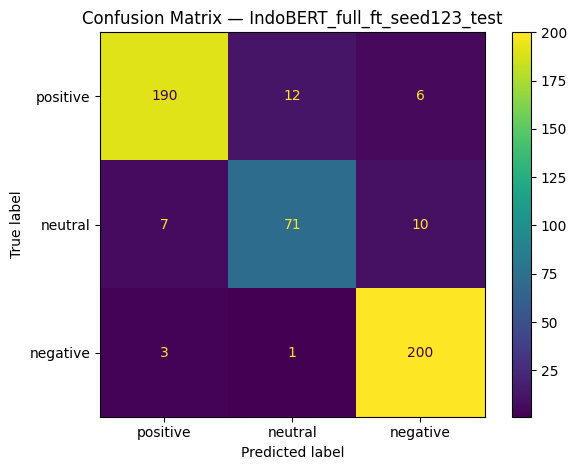

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

RUN_ID_TO_PLOT = f"{all_results.loc[all_results['val_macro_f1'].idxmax(), 'run_id']}_test"
confusion_path = os.path.join(CONFUSION_DIR, f"{RUN_ID_TO_PLOT}_confusion_matrix.csv")

if os.path.exists(confusion_path):
    confusion_df = pd.read_csv(confusion_path, index_col=0)
    cm_values = confusion_df.to_numpy()
    label_names = [ID2LABEL[index] for index in range(NUM_LABELS)]

    display_labels = ConfusionMatrixDisplay(
        confusion_matrix=cm_values,
        display_labels=label_names,
    )
    display_labels.plot(values_format="d")
    plt.title(f"Confusion Matrix — {RUN_ID_TO_PLOT}")
    plt.tight_layout()
    plt.show()
else:
    print("Confusion matrix belum tersedia. Jalankan eksperimen terkait terlebih dahulu.")


In [21]:
# ==============================================================================
# TAHAP 3 (REVISI FINAL v4): STRATEGI PEMBANDING + BEST CHECKPOINT + TEST SET
# ==============================================================================
STRATEGY_LR = {
    "full_fine_tuning": 2e-5,
    "partial_freezing": 2e-5,
    "linear_probing": 2e-3,
}

STRATEGIES_TO_RUN = ["partial_freezing", "linear_probing"]

STRATEGY_CONFIG_CODE = "compare_strategies_train6k_bestep_testall_ml128_bs16_ep3_v4"
STRATEGY_RESULTS_CSV = os.path.join(RESULTS_DIR, f"hasil_smsa_{STRATEGY_CONFIG_CODE}.csv")
COMBINED_RESULTS_CSV = os.path.join(RESULTS_DIR, "hasil_smsa_train6k_bestep_testall_all_strategies_v4.csv")
COMBINED_AGGREGATE_CSV = os.path.join(RESULTS_DIR, "rekap_agregat_smsa_train6k_bestep_testall_all_strategies_v4.csv")


def apply_finetuning_strategy(model, model_key, strategy):
    """Menerapkan pembekuan layer (freezing) secara eksplisit sesuai strategi."""
    if strategy == "full_fine_tuning":
        for param in model.parameters():
            param.requires_grad = True
        return

    for param in model.parameters():
        param.requires_grad = False

    if strategy == "linear_probing":
        for param in model.classifier.parameters():
            param.requires_grad = True
        if model_key == "DistilBERT" and hasattr(model, "pre_classifier"):
            for param in model.pre_classifier.parameters():
                param.requires_grad = True

    elif strategy == "partial_freezing":
        if model_key in ["BERT", "IndoBERT"]:
            for layer in model.bert.encoder.layer[6:]:
                for param in layer.parameters():
                    param.requires_grad = True
            if hasattr(model.bert, "pooler") and model.bert.pooler is not None:
                for param in model.bert.pooler.parameters():
                    param.requires_grad = True
            for param in model.classifier.parameters():
                param.requires_grad = True
        elif model_key == "DistilBERT":
            for layer in model.distilbert.transformer.layer[3:]:
                for param in layer.parameters():
                    param.requires_grad = True
            for param in model.pre_classifier.parameters():
                param.requires_grad = True
            for param in model.classifier.parameters():
                param.requires_grad = True
    else:
        raise ValueError(f"Strategi tidak dikenal: {strategy}")


def run_strategy_experiment(model_key, strategy, seed):
    """Menjalankan strategi pembanding, memuat best checkpoint, dan mengevaluasi Test Set satu kali."""
    model_id = MODEL_CONFIGS[model_key]
    lr = STRATEGY_LR[strategy]
    run_id = f"{model_key}_{strategy}_seed{seed}"

    if os.path.exists(STRATEGY_RESULTS_CSV):
        prev = pd.read_csv(STRATEGY_RESULTS_CSV)
        if run_id in set(prev["run_id"].astype(str)):
            print(f"{run_id} sudah ada di CSV. Run dilewati.")
            return None

    print(f"\n{'='*70}\nRUN: {run_id} | LR: {lr}\n{'='*70}")
    set_reproducible_seed(seed)
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    tokenizer = get_tokenizer(model_key, model_id)
    train_loader, valid_loader = build_dataloaders(tokenizer, seed)

    test_dataset = SmSADataset(clean_splits["test"], tokenizer, MAX_LENGTH)
    test_loader = DataLoader(
        test_dataset,
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_id,
        num_labels=NUM_LABELS,
        id2label=ID2LABEL,
        label2id=LABEL2ID,
    )
    model.config.problem_type = "single_label_classification"
    apply_finetuning_strategy(model, model_key, strategy)
    model.to(DEVICE)

    total_params, trainable_params = count_parameters(model)
    print(f"Total parameter: {total_params:,} | Trainable: {trainable_params:,}")

    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr,
        weight_decay=WEIGHT_DECAY,
    )
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    training_time_seconds = 0.0
    epoch_losses = []
    epoch_val_f1s = []

    best_val_f1 = -1.0
    best_epoch = 1
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"{run_id}_best.pt")

    for epoch in range(EPOCHS):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t_start = time.perf_counter()

        epoch_loss = train_one_epoch(model, train_loader, optimizer, scaler)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        training_time_seconds += time.perf_counter() - t_start
        epoch_losses.append(epoch_loss)

        epoch_metrics = evaluate_model(model, valid_loader)
        curr_val_f1 = epoch_metrics["val_macro_f1"]
        curr_val_acc = epoch_metrics["val_accuracy"]
        epoch_val_f1s.append(curr_val_f1)

        tag = ""
        if curr_val_f1 > best_val_f1:
            best_val_f1 = curr_val_f1
            best_epoch = epoch + 1
            torch.save(model.state_dict(), ckpt_path)
            tag = " <-- [BEST CHECKPOINT SAVED]"

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | Train Loss: {epoch_loss:.4f} | "
            f"Val Acc: {curr_val_acc:.4f} | Val Macro F1: {curr_val_f1:.4f}{tag}"
        )

    print(f"Memuat checkpoint terbaik dari Epoch {best_epoch} ({os.path.basename(ckpt_path)})...")
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))

    val_metrics = evaluate_model(model, valid_loader)
    val_report_path, val_confusion_path = save_evaluation_diagnostics(f"{run_id}_val", val_metrics)

    test_metrics = evaluate_model(model, test_loader)
    test_report_path, test_confusion_path = save_evaluation_diagnostics(f"{run_id}_test", test_metrics)

    print(
        f"Hasil Best Checkpoint (Epoch {best_epoch}) -> "
        f"Val Macro F1: {val_metrics['val_macro_f1']:.5f} | "
        f"Test Acc: {test_metrics['val_accuracy']:.5f} | "
        f"Test Macro F1: {test_metrics['val_macro_f1']:.5f}"
    )

    peak_gpu_memory_mb = torch.cuda.max_memory_allocated() / (1024 ** 2) if DEVICE.type == "cuda" else float("nan")
    kept_ckpt = manage_best_group_checkpoint(model_key, strategy, seed, best_val_f1, ckpt_path, STRATEGY_RESULTS_CSV)

    result = {
        "run_id": run_id,
        "config_code": STRATEGY_CONFIG_CODE,
        "model_key": model_key,
        "model_id": model_id,
        "strategy": strategy,
        "seed": seed,
        "best_epoch": best_epoch,
        "saved_checkpoint_path": kept_ckpt,
        "max_length": MAX_LENGTH,
        "train_batch_size": TRAIN_BATCH_SIZE,
        "eval_batch_size": EVAL_BATCH_SIZE,
        "epochs": EPOCHS,
        "learning_rate": lr,
        "weight_decay": WEIGHT_DECAY,
        "val_accuracy": val_metrics["val_accuracy"],
        "val_macro_f1": val_metrics["val_macro_f1"],
        "test_accuracy": test_metrics["val_accuracy"],
        "test_macro_f1": test_metrics["val_macro_f1"],
        "training_time_seconds": training_time_seconds,
        "inference_time_ms_per_sentence": test_metrics["inference_time_ms_per_sentence"],
        "inference_samples_per_second": test_metrics["inference_samples_per_second"],
        "total_parameters": total_params,
        "trainable_parameters": trainable_params,
        "peak_gpu_memory_mb": peak_gpu_memory_mb,
        "classification_report_csv": val_report_path,
        "confusion_matrix_csv": val_confusion_path,
        "test_classification_report_csv": test_report_path,
        "test_confusion_matrix_csv": test_confusion_path,
    }

    for idx, (e_loss, e_f1) in enumerate(zip(epoch_losses, epoch_val_f1s), start=1):
        result[f"train_loss_epoch_{idx}"] = e_loss
        result[f"val_macro_f1_epoch_{idx}"] = e_f1

    for label_name in [ID2LABEL[i] for i in range(NUM_LABELS)]:
        val_cls = val_metrics["classification_report"][label_name]
        result[f"val_precision_{label_name}"] = val_cls["precision"]
        result[f"val_recall_{label_name}"] = val_cls["recall"]
        result[f"val_f1_{label_name}"] = val_cls["f1-score"]

        test_cls = test_metrics["classification_report"][label_name]
        result[f"test_precision_{label_name}"] = test_cls["precision"]
        result[f"test_recall_{label_name}"] = test_cls["recall"]
        result[f"test_f1_{label_name}"] = test_cls["f1-score"]

    res_df = pd.DataFrame([result])
    file_exists = os.path.exists(STRATEGY_RESULTS_CSV)
    res_df.to_csv(STRATEGY_RESULTS_CSV, mode="a", header=not file_exists, index=False)

    del model, optimizer, scaler, train_loader, valid_loader, test_loader, test_dataset
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return result


for strat in STRATEGIES_TO_RUN:
    for m_key in MODEL_CONFIGS:
        for s in SEEDS:
            run_strategy_experiment(m_key, strat, s)

# Gabungkan seluruh 27 run (Full FT + Strategi Pembanding)
df_full = pd.read_csv(RESULTS_CSV)
df_strat = pd.read_csv(STRATEGY_RESULTS_CSV)
all_results = pd.concat([df_full, df_strat], ignore_index=True)
all_results.to_csv(COMBINED_RESULTS_CSV, index=False)

metric_cols = [
    "val_accuracy",
    "val_macro_f1",
    "test_accuracy",
    "test_macro_f1",
    "best_epoch",
    "training_time_seconds",
    "inference_time_ms_per_sentence",
    "total_parameters",
    "trainable_parameters",
    "peak_gpu_memory_mb",
]
all_aggregate = (
    all_results.groupby(["model_key", "strategy"])[metric_cols]
    .agg(["mean", "std"])
)
all_aggregate.columns = [f"{m}_{stat}" for m, stat in all_aggregate.columns]
all_aggregate = all_aggregate.reset_index()
all_aggregate.to_csv(COMBINED_AGGREGATE_CSV, index=False)

print("\n=== REKAP AGREGAT VALIDATION & TEST SET (SELURUH 27 RUN) ===")
display(all_aggregate)


RUN: BERT_partial_freezing_seed42 | LR: 2e-05


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total parameter: 177,855,747 | Trainable: 43,120,131
Epoch 1/3 | Train Loss: 0.5354 | Val Acc: 0.7929 | Val Macro F1: 0.7652 <-- [BEST CHECKPOINT SAVED]
Epoch 2/3 | Train Loss: 0.3933 | Val Acc: 0.8539 | Val Macro F1: 0.7934 <-- [BEST CHECKPOINT SAVED]
Epoch 3/3 | Train Loss: 0.3171 | Val Acc: 0.8740 | Val Macro F1: 0.8338 <-- [BEST CHECKPOINT SAVED]
Memuat checkpoint terbaik dari Epoch 3 (BERT_partial_freezing_seed42_best.pt)...
Classification report disimpan: /kaggle/working/studio3_results/classification_reports/BERT_partial_freezing_seed42_val_classification_report.csv
Confusion matrix disimpan: /kaggle/working/studio3_results/confusion_matrices/BERT_partial_freezing_seed42_val_confusion_matrix.csv


,precision,recall,f1-score,support
positive,0.892487,0.946429,0.918667,728.000000
neutral,0.841121,0.697674,0.762712,129.000000
negative,0.844687,0.796915,0.820106,389.000000
accuracy,0.873997,0.873997,0.873997,0.873997
macro avg,0.859432,0.813673,0.833828,1246.000000
weighted avg,0.872246,0.873997,0.871750,1246.000000


,predicted_positive,predicted_neutral,predicted_negative
actual_positive,689,6,33
actual_neutral,15,90,24
actual_negative,68,11,310


... (160 outputs left out)

,precision,recall,f1-score,support
positive,0.859223,0.850962,0.855072,208.000
neutral,0.891304,0.465909,0.611940,88.000
negative,0.806452,0.980392,0.884956,204.000
accuracy,0.836000,0.836000,0.836000,0.836
macro avg,0.852326,0.765754,0.783990,500.000
weighted avg,0.843339,0.836000,0.824474,500.000


,predicted_positive,predicted_neutral,predicted_negative
actual_positive,177,4,27
actual_neutral,26,41,21
actual_negative,3,1,200


Hasil Best Checkpoint (Epoch 3) -> Val Macro F1: 0.86243 | Test Acc: 0.83600 | Test Macro F1: 0.78399

=== REKAP AGREGAT VALIDATION & TEST SET (SELURUH 27 RUN) ===


,model_key,strategy,val_accuracy_mean,val_accuracy_std,val_macro_f1_mean,val_macro_f1_std,test_accuracy_mean,test_accuracy_std,test_macro_f1_mean,test_macro_f1_std,...,training_time_seconds_mean,training_time_seconds_std,inference_time_ms_per_sentence_mean,inference_time_ms_per_sentence_std,total_parameters_mean,total_parameters_std,trainable_parameters_mean,trainable_parameters_std,peak_gpu_memory_mb_mean,peak_gpu_memory_mb_std
0,BERT,full_fine_tuning,0.887105,0.008353,0.851557,0.009848,0.796667,0.051160,0.745223,0.045103,...,177.930227,0.636568,1.680862,0.012910,177855747.0,0.0,177855747.0,0.0,3458.006673,5.385338
1,BERT,linear_probing,0.776351,0.007712,0.676681,0.020981,0.546667,0.031262,0.480287,0.045130,...,34.630131,0.063270,1.697022,0.010279,177855747.0,0.0,2307.0,0.0,1376.748535,0.000000
2,BERT,partial_freezing,0.869449,0.010035,0.830752,0.008731,0.769333,0.045004,0.733501,0.032721,...,82.737367,0.012980,1.693381,0.006261,177855747.0,0.0,43120131.0,0.0,1894.928223,0.000000
3,DistilBERT,full_fine_tuning,0.886570,0.000463,0.846376,0.005475,0.806000,0.015620,0.750753,0.021782,...,109.512911,0.045088,0.856570,0.007581,135326979.0,0.0,135326979.0,0.0,2628.257324,0.000000
4,DistilBERT,linear_probing,0.789192,0.017442,0.725729,0.011501,0.562000,0.020785,0.503786,0.019634,...,17.855389,0.019351,0.862989,0.009742,135326979.0,0.0,592899.0,0.0,1060.534668,0.000000
5,DistilBERT,partial_freezing,0.850187,0.012799,0.804350,0.018007,0.749333,0.016773,0.709003,0.016972,...,41.165185,0.024165,0.851915,0.007748,135326979.0,0.0,21856515.0,0.0,1316.112793,0.000000
6,IndoBERT,full_fine_tuning,0.928036,0.004420,0.900289,0.006076,0.916667,0.007572,0.888890,0.016311,...,152.212876,0.179158,1.692811,0.004319,124443651.0,0.0,124443651.0,0.0,2466.020996,0.000000
7,IndoBERT,linear_probing,0.891118,0.007457,0.856751,0.004955,0.817333,0.017243,0.766434,0.022087,...,34.637519,0.048353,1.687487,0.005226,124443651.0,0.0,2307.0,0.0,968.748535,0.000000
8,IndoBERT,partial_freezing,0.926699,0.001226,0.896170,0.003850,0.916667,0.011547,0.892960,0.013984,...,82.578894,0.053343,1.693802,0.001558,124443651.0,0.0,43120131.0,0.0,1486.942871,0.000000


In [22]:
# ==============================================================================
# TAHAP 4A (BAGIAN 1): BASELINE TF-IDF + LOGISTIC REGRESSION (TRAIN 6.000)
# ==============================================================================
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

assert len(clean_splits["train"]) == 6000, (
    f"Error: Ukuran data latih adalah {len(clean_splits['train'])}, seharusnya 6.000 sampel!"
)

tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=20000)
X_train_tfidf = tfidf.fit_transform(clean_splits["train"]["text"])
X_val_tfidf = tfidf.transform(clean_splits["validation"]["text"])
X_test_tfidf = tfidf.transform(clean_splits["test"]["text"])

clf_tfidf = LogisticRegression(max_iter=1000, random_state=42)
clf_tfidf.fit(X_train_tfidf, clean_splits["train"]["label_id"])

val_pred_tfidf = clf_tfidf.predict(X_val_tfidf)
test_pred_tfidf = clf_tfidf.predict(X_test_tfidf)

tfidf_val_acc = accuracy_score(clean_splits["validation"]["label_id"], val_pred_tfidf)
tfidf_val_f1 = f1_score(clean_splits["validation"]["label_id"], val_pred_tfidf, average="macro")
tfidf_test_acc = accuracy_score(clean_splits["test"]["label_id"], test_pred_tfidf)
tfidf_test_f1 = f1_score(clean_splits["test"]["label_id"], test_pred_tfidf, average="macro")

baseline_row = {
    "model_key": "Baseline_TFIDF_LogReg",
    "train_samples": len(clean_splits["train"]),
    "val_samples": len(clean_splits["validation"]),
    "test_samples": len(clean_splits["test"]),
    "val_accuracy": tfidf_val_acc,
    "val_macro_f1": tfidf_val_f1,
    "test_accuracy": tfidf_test_acc,
    "test_macro_f1": tfidf_test_f1,
}

BASELINE_CSV = os.path.join(RESULTS_DIR, "baseline_tfidf_train6k_v4.csv")
pd.DataFrame([baseline_row]).to_csv(BASELINE_CSV, index=False)

print("=== HASIL BASELINE TF-IDF + LOGISTIC REGRESSION (SUBSET TRAIN 6.000) ===")
print(f"Validation Accuracy : {tfidf_val_acc:.5f}")
print(f"Validation Macro F1 : {tfidf_val_f1:.5f}")
print(f"Test Accuracy       : {tfidf_test_acc:.5f}")
print(f"Test Macro F1       : {tfidf_test_f1:.5f}")
print(f"Tersimpan ke        : {BASELINE_CSV}")
print(
    "\nCatatan Pelaporan: Angka ~0,73 pada soal studi kasus merupakan angka acuan referensi. "
    f"Hasil aktual Test Macro F1 sebesar {tfidf_test_f1:.5f} dilaporkan sebagai baseline empiris subset 6.000 sampel."
)

=== HASIL BASELINE TF-IDF + LOGISTIC REGRESSION (SUBSET TRAIN 6.000) ===
Validation Accuracy : 0.86517
Validation Macro F1 : 0.78910
Test Accuracy       : 0.73200
Test Macro F1       : 0.62996
Tersimpan ke        : /kaggle/working/studio3_results/baseline_tfidf_train6k_v4.csv

Catatan Pelaporan: Angka ~0,73 pada soal studi kasus merupakan angka acuan referensi. Hasil aktual Test Macro F1 sebesar 0.62996 dilaporkan sebagai baseline empiris subset 6.000 sampel.



=== PERBANDINGAN VALIDATION vs TEST SET (MEAN & STD DARI BEST CHECKPOINT) ===


,model_key,strategy,best_epoch_mean,val_macro_f1_mean,val_macro_f1_std,test_accuracy_mean,test_accuracy_std,test_macro_f1_mean,test_macro_f1_std,inference_time_ms_per_sentence_mean
6,IndoBERT,full_fine_tuning,1.333333,0.900289,0.006076,0.916667,0.007572,0.888890,0.016311,1.692811
8,IndoBERT,partial_freezing,2.333333,0.896170,0.003850,0.916667,0.011547,0.892960,0.013984,1.693802
7,IndoBERT,linear_probing,3.000000,0.856751,0.004955,0.817333,0.017243,0.766434,0.022087,1.687487
0,BERT,full_fine_tuning,2.333333,0.851557,0.009848,0.796667,0.051160,0.745223,0.045103,1.680862
3,DistilBERT,full_fine_tuning,3.000000,0.846376,0.005475,0.806000,0.015620,0.750753,0.021782,0.856570
2,BERT,partial_freezing,3.000000,0.830752,0.008731,0.769333,0.045004,0.733501,0.032721,1.693381
5,DistilBERT,partial_freezing,3.000000,0.804350,0.018007,0.749333,0.016773,0.709003,0.016972,0.851915
4,DistilBERT,linear_probing,2.333333,0.725729,0.011501,0.562000,0.020785,0.503786,0.019634,0.862989
1,BERT,linear_probing,2.000000,0.676681,0.020981,0.546667,0.031262,0.480287,0.045130,1.697022



=== DETAIL TEST SET RUN PEMENANG: IndoBERT_full_ft_seed123 (Best Epoch: 1) ===
Checkpoint tersimpan : /kaggle/working/studio3_results/checkpoints/IndoBERT_full_ft_seed123_best.pt
Val Macro F1         : 0.90560
Test Accuracy        : 0.92200
Test Macro F1        : 0.90311
Test Inference       : 1.69172 ms/kalimat


,precision,recall,f1-score,support
class,,,,
positive,0.950000,0.913462,0.931373,208.000
neutral,0.845238,0.806818,0.825581,88.000
negative,0.925926,0.980392,0.952381,204.000
accuracy,0.922000,0.922000,0.922000,0.922
macro avg,0.907055,0.900224,0.903112,500.000
weighted avg,0.921740,0.922000,0.921325,500.000


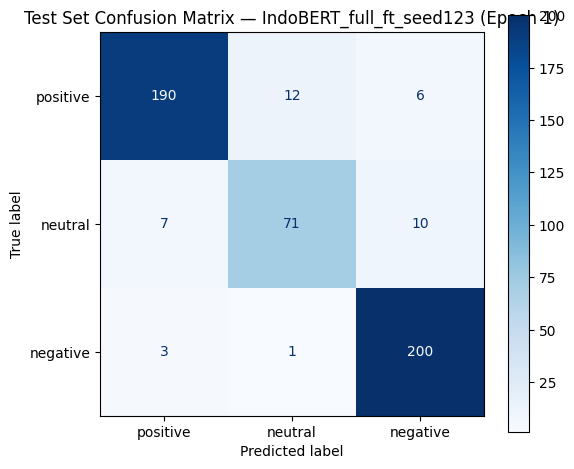

In [23]:
# Bagian 2: Ringkasan Performa Validation vs Test Set untuk Seluruh Kombinasi (Mean ± SD)
df_all = pd.read_csv(COMBINED_RESULTS_CSV)
df_agg = pd.read_csv(COMBINED_AGGREGATE_CSV)

summary_cols = [
    "model_key",
    "strategy",
    "best_epoch_mean",
    "val_macro_f1_mean",
    "val_macro_f1_std",
    "test_accuracy_mean",
    "test_accuracy_std",
    "test_macro_f1_mean",
    "test_macro_f1_std",
    "inference_time_ms_per_sentence_mean",
]
print("\n=== PERBANDINGAN VALIDATION vs TEST SET (MEAN & STD DARI BEST CHECKPOINT) ===")
display(df_agg[summary_cols].sort_values(by="val_macro_f1_mean", ascending=False))

# Bagian 3: Detail Evaluasi Test Set dari Run Terbaik (Dipilih Berdasarkan Val Macro F1 Tertinggi)
best_run_row = df_all.loc[df_all["val_macro_f1"].idxmax()]
print(
    f"\n=== DETAIL TEST SET RUN PEMENANG: {best_run_row['run_id']} "
    f"(Best Epoch: {int(best_run_row['best_epoch'])}) ==="
)
print(f"Checkpoint tersimpan : {best_run_row['saved_checkpoint_path']}")
print(f"Val Macro F1         : {best_run_row['val_macro_f1']:.5f}")
print(f"Test Accuracy        : {best_run_row['test_accuracy']:.5f}")
print(f"Test Macro F1        : {best_run_row['test_macro_f1']:.5f}")
print(f"Test Inference       : {best_run_row['inference_time_ms_per_sentence']:.5f} ms/kalimat")

display(pd.read_csv(best_run_row["test_classification_report_csv"], index_col=0))

cm_best_test = pd.read_csv(best_run_row["test_confusion_matrix_csv"], index_col=0).values
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best_test,
    display_labels=[ID2LABEL[i] for i in range(NUM_LABELS)],
)
disp.plot(ax=ax, values_format="d", cmap="Blues")
plt.title(f"Test Set Confusion Matrix — {best_run_row['run_id']} (Epoch {int(best_run_row['best_epoch'])})")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "confusion_matrix_best_test_v4.png"), dpi=200)
plt.show()

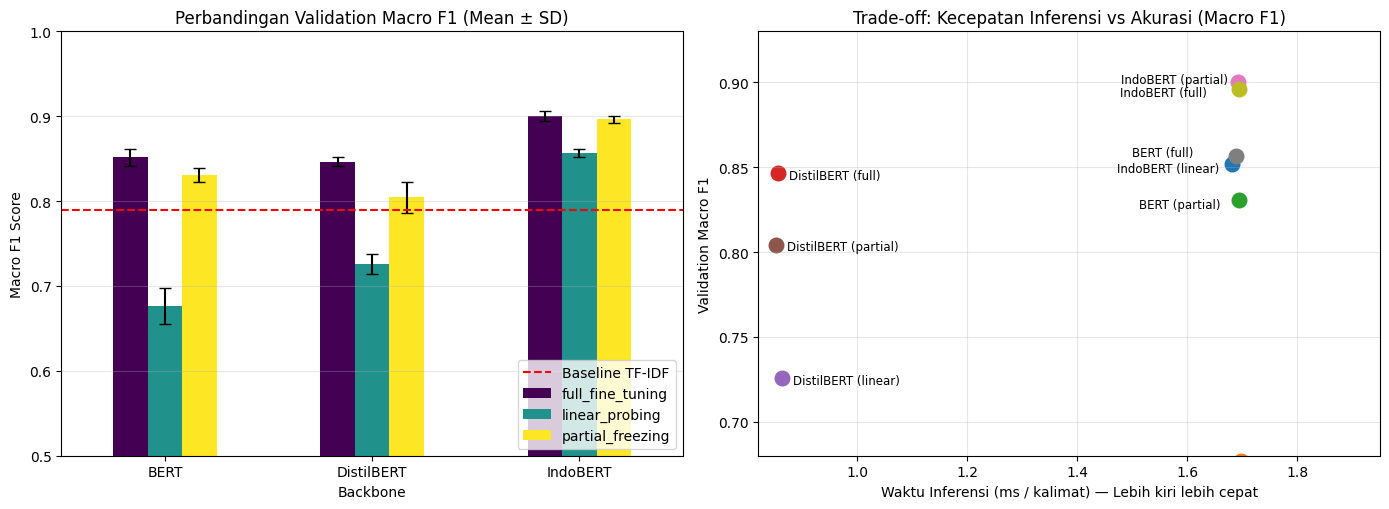

In [24]:
# ==============================================================================
# TAHAP 4B: VISUALISASI PERBANDINGAN BACKBONE & STRATEGI FINE-TUNING
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Plot 1: Grouped Bar Chart Val Macro F1 (Mean ± SD)
pivot_mean = all_aggregate.pivot(index="model_key", columns="strategy", values="val_macro_f1_mean")
pivot_std = all_aggregate.pivot(index="model_key", columns="strategy", values="val_macro_f1_std")

pivot_mean.plot(kind="bar", yerr=pivot_std, capsize=4, ax=axes[0], rot=0, colormap="viridis")
axes[0].axhline(
    y=f1_score(clean_splits["validation"]["label_id"], val_pred_tfidf, average="macro"),
    color="red",
    linestyle="--",
    label="Baseline TF-IDF",
)
axes[0].set_title("Perbandingan Validation Macro F1 (Mean ± SD)")
axes[0].set_ylabel("Macro F1 Score")
axes[0].set_xlabel("Backbone")
axes[0].set_ylim(0.5, 1.0)
axes[0].legend(loc="lower right")
axes[0].grid(axis="y", alpha=0.3)

label_offsets = {
    ("IndoBERT", "partial_freezing"): (-85, 4),
    ("IndoBERT", "full_fine_tuning"): (-85, -10),
    ("IndoBERT", "linear_probing"): (-85, -12),
    ("BERT", "full_fine_tuning"): (-72, 6),
    ("BERT", "partial_freezing"): (-72, -6),
    ("BERT", "linear_probing"): (-72, 6),
    ("DistilBERT", "full_fine_tuning"): (8, -4),
    ("DistilBERT", "partial_freezing"): (8, -4),
    ("DistilBERT", "linear_probing"): (8, -4),
}

# Plot 2: Trade-off Waktu Inferensi (ms/kalimat) vs Macro F1
for (m_key, strat), row in all_aggregate.set_index(["model_key", "strategy"]).iterrows():
    x_val = row["inference_time_ms_per_sentence_mean"]
    y_val = row["val_macro_f1_mean"]
    axes[1].scatter(x_val, y_val, s=110)
    dx, dy = label_offsets.get((m_key, strat), (5, 5))
    axes[1].annotate(
        f"{m_key} ({strat.split('_')[0]})",
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        fontsize=8.5,
    )

axes[1].set_title("Trade-off: Kecepatan Inferensi vs Akurasi (Macro F1)")
axes[1].set_xlabel("Waktu Inferensi (ms / kalimat) — Lebih kiri lebih cepat")
axes[1].set_ylabel("Validation Macro F1")
axes[1].set_xlim(0.82, 1.95)
axes[1].set_ylim(0.68, 0.93)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "grafik_perbandingan_studio3_clean.png"), dpi=200)
plt.show()

In [25]:
# ==============================================================================
# HELPER: MENCETAK ANGKA FINAL UNTUK KESIMPULAN Q1–Q3 (DARI HASIL v4)
# ==============================================================================
df_agg = pd.read_csv(COMBINED_AGGREGATE_CSV)
df_base = pd.read_csv(BASELINE_CSV).iloc[0]

print(f"Baseline TF-IDF (6.000 train) -> Val Macro F1: {df_base['val_macro_f1']:.4f} | Test Macro F1: {df_base['test_macro_f1']:.4f}\n")
print("=== RINGKASAN PER KOMBINASI (MEAN ± STD) ===")
for _, r in df_agg.sort_values(by="val_macro_f1_mean", ascending=False).iterrows():
    print(
        f"{r['model_key']:10s} | {r['strategy']:16s} | "
        f"Val F1: {r['val_macro_f1_mean']:.4f} ± {r['val_macro_f1_std']:.4f} | "
        f"Test F1: {r['test_macro_f1_mean']:.4f} ± {r['test_macro_f1_std']:.4f} | "
        f"Train: {r['training_time_seconds_mean']:.1f}s | "
        f"Infer: {r['inference_time_ms_per_sentence_mean']:.2f} ms/kalimat"
    )

Baseline TF-IDF (6.000 train) -> Val Macro F1: 0.7891 | Test Macro F1: 0.6300

=== RINGKASAN PER KOMBINASI (MEAN ± STD) ===
IndoBERT   | full_fine_tuning | Val F1: 0.9003 ± 0.0061 | Test F1: 0.8889 ± 0.0163 | Train: 152.2s | Infer: 1.69 ms/kalimat
IndoBERT   | partial_freezing | Val F1: 0.8962 ± 0.0038 | Test F1: 0.8930 ± 0.0140 | Train: 82.6s | Infer: 1.69 ms/kalimat
IndoBERT   | linear_probing   | Val F1: 0.8568 ± 0.0050 | Test F1: 0.7664 ± 0.0221 | Train: 34.6s | Infer: 1.69 ms/kalimat
BERT       | full_fine_tuning | Val F1: 0.8516 ± 0.0098 | Test F1: 0.7452 ± 0.0451 | Train: 177.9s | Infer: 1.68 ms/kalimat
DistilBERT | full_fine_tuning | Val F1: 0.8464 ± 0.0055 | Test F1: 0.7508 ± 0.0218 | Train: 109.5s | Infer: 0.86 ms/kalimat
BERT       | partial_freezing | Val F1: 0.8308 ± 0.0087 | Test F1: 0.7335 ± 0.0327 | Train: 82.7s | Infer: 1.69 ms/kalimat
DistilBERT | partial_freezing | Val F1: 0.8044 ± 0.0180 | Test F1: 0.7090 ± 0.0170 | Train: 41.2s | Infer: 0.85 ms/kalimat
DistilBERT |

# Kesimpulan & Jawaban Pertanyaan Riset Wajib (Q1–Q3)

## Q1: Backbone dengan Trade-off Akurasi vs Efisiensi Terbaik
- **IndoBERT (`indobenchmark/indobert-base-p1`)** memberikan *trade-off* akurasi dan efisiensi terbaik secara keseluruhan pada subset latih 6.000 sampel. Pada skenario *Full Fine-Tuning*, IndoBERT meraih **Val Macro F1 = `0.9003 ± 0.0061`** dan **Test Macro F1 = `0.8889 ± 0.0163`**, mengungguli *BERT multilingual* (`Val Macro F1 = 0.8516 ± 0.0098`, `Test Macro F1 = 0.7452 ± 0.0451`) maupun *DistilBERT multilingual* (`Val Macro F1 = 0.8464 ± 0.0055`, `Test Macro F1 = 0.7508 ± 0.0218`), serta jauh melampaui *baseline* empiris **TF-IDF + Logistic Regression** (`Val Macro F1 = 0.7891`, `Test Macro F1 = 0.6300`, dibandingkan angka acuan referensi ~0,73 pada soal studi kasus).
- Dari sisi efisiensi parameter, IndoBERT juga paling ringkas (**124,44 juta parameter**) dibandingkan BERT (`177,86 juta`) dan DistilBERT (`135,33 juta`), dengan waktu inferensi rata-rata **`1.69` ms/kalimat**.
- **DistilBERT** mencatat waktu inferensi tercepat (**`0.86` ms/kalimat** pada *Full Fine-Tuning* dan **`0.85` ms/kalimat** pada *Partial Freezing*, sekitar 2× lebih cepat daripada BERT dan IndoBERT) serta waktu pelatihan paling singkat (`109.5` detik pada *Full Fine-Tuning*), sehingga menjadi pilihan alternatif apabila sistem menuntut latensi *real-time* yang ketat.

## Q2: Apakah Strategi Hemat Komputasi Kompetitif dibanding Full Fine-Tuning?
- Evaluasi dilakukan dengan membandingkan selisih nilai rata-rata (`mean`) Macro F1 antarstrategi terhadap **variasi antar-*seed* (simpangan baku / `SD`)** sebagai indikator kestabilan lintas percobaan (catatan: perbandingan selisih rata-rata terhadap simpangan baku merupakan analisis deskriptif kestabilan eksperimen, bukan pengujian signifikansi statistik formal).
- **Partial Freezing** terbukti sangat kompetitif terhadap *Full Fine-Tuning*:
  - Pada **IndoBERT**, *Partial Freezing* (`43,12 juta` parameter dilatih, waktu latih rata-rata **`82.6` detik**) menghasilkan **Val Macro F1 = `0.8962 ± 0.0038`** dan **Test Macro F1 = `0.8930 ± 0.0140`** dibandingkan *Full Fine-Tuning* (`Val Macro F1 = 0.9003 ± 0.0061`, `Test Macro F1 = 0.8889 ± 0.0163`, waktu latih `152.2` detik). Selisih performa validasi keduanya (`0.0041`) lebih kecil daripada simpangan baku *Full Fine-Tuning* (`0.0061`), sementara pada *test set* rata-ratanya justru sedikit lebih tinggi dengan pemangkasan waktu pelatihan hampir separuhnya (45,7%).
  - Pada **BERT** (`Val Macro F1 = 0.8308 ± 0.0087`, `Test Macro F1 = 0.7335 ± 0.0327`) dan **DistilBERT** (`Val Macro F1 = 0.8044 ± 0.0180`, `Test Macro F1 = 0.7090 ± 0.0170`), *Partial Freezing* menurunkan Macro F1 secara konsisten melampaui rentang variasi antar-*seed*-nya, namun tetap mengungguli *baseline* TF-IDF (`0.6300`) dengan penghematan waktu latih lebih dari 50%.
- **Linear Probing** memangkas waktu pelatihan paling drastis (`17.9–34.6` detik, hanya melatih *classification head*), namun menghasilkan penurunan Macro F1 yang tajam pada *BERT* (`Test Macro F1 = 0.4803 ± 0.0451`) dan *DistilBERT* (`Test Macro F1 = 0.5038 ± 0.0196`) karena bobot encoder tidak disesuaikan dengan tugas sentimen. Sebaliknya, pada **IndoBERT**, *Linear Probing* tetap meraih **Val Macro F1 = `0.8568 ± 0.0050`** dan **Test Macro F1 = `0.7664 ± 0.0221`**, melampaui *Full Fine-Tuning* dari kedua model multibahasa karena representasi bahasa Indonesia bawaannya sudah kuat.

## Q3: Rekomendasi Kombinasi Final
- **Kriteria Pemilihan**: Memaksimalkan **Macro F1** pada *validation* dan *test set* (agar kelas minoritas `neutral` tetap terklasifikasi dengan baik), menjaga kestabilan rendahnya variansi antar-*seed* (`SD`), efisiensi waktu serta memori pelatihan, dan latensi inferensi di bawah `2 ms/kalimat`.
- **Rekomendasi Utama — `IndoBERT + Full Fine-Tuning` (dengan `IndoBERT + Partial Freezing` sebagai opsi efisiensi tinggi)**:
  - Berdasarkan peringkat validasi tertinggi, **`IndoBERT + Full Fine-Tuning`** menempati urutan pertama dengan **Val Macro F1 = `0.9003 ± 0.0061`** dan teruji pada **Test Set** dengan **Test Macro F1 = `0.8889 ± 0.0163`** (unggul `+0.2589` poin di atas *baseline* TF-IDF `0.6300`), ukuran model paling ringkas (`124,44 juta` parameter), serta latensi inferensi **`1.69` ms/kalimat**.
  - Apabila pelatihan ulang berkala atau efisiensi komputasi menjadi prioritas, **`IndoBERT + Partial Freezing`** sangat layak dipilih karena mempertahankan kestabilan tertinggi (**Val Macro F1 = `0.8962 ± 0.0038`**, **Test Macro F1 = `0.8930 ± 0.0140`**) hanya dengan melatih 34,6% parameter (`43,12 juta`) dalam waktu **`82.6` detik**.